This test is on
1. i.i.d. rayleigh fading channel
2. 4*4 MIMO channel
3. 1000 symbols per channel
4. total of 1000 channels

ver 11.24.04.35


In [6]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!cd /content
!rm -rf EE_MIMO_PROJECT
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
%pip install -r requirements.txt
# change the dir
!ls
# just for checking that the current folder is correct

Cloning into 'EE_MIMO_PROJECT'...
remote: Enumerating objects: 384, done.
remote: Counting objects: 100% (384/384), done.
remote: Compressing objects: 100% (273/273), done.
remote: Total 384 (delta 162), reused 251 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (384/384), 7.47 MiB | 19.37 MiB/s, done.
Resolving deltas: 100% (162/162), done.
/content/EE_MIMO_PROJECT/EE_MIMO_PROJECT
NYCU_scene  requirements.txt  simulation_results  src


In [ ]:
# import models
from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

In [8]:
# mimo settings
import torch
from src.channel.rayleighfading import rayleighfading
BLOCKS = 100000
SYMBOLS_PER_CHANNEL = 1
# total of (SYMBOLS_PER_CHANNEL * BLOCKS) symbols are transmitted
NT = 4
NR = 4
SNR_DB = list(range(0, 21, 2))

def generateChannel(NR, NT):
    return rayleighfading(NR=NR, NT=NT)

qpsk = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
symbol_qpsk = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])
bpsk = torch.tensor([-1, 1], dtype=torch.complex128) / 2**0.5
symbol_bpsk = torch.tensor([[0], [1]])

In [ ]:
from pathlib import Path
from tempfile import mkdtemp

from src.channel.testbench import Testbench

# Use a fresh directory because Partial MAP appends rows to its CSV files.
pmap_log_dir = Path(mkdtemp(prefix="rayleigh_pmap_"))
models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": partialMAP(verbose=False, csv_log_dir=pmap_log_dir),
}

bench = Testbench(models, bpsk, symbol_bpsk, SYMBOLS_PER_CHANNEL, SNR_DB)
csi = torch.stack([generateChannel(NR=NR, NT=NT) for _ in range(BLOCKS)])
ERROR_CSV = "rayleigh_bit_errors.csv"
ber, bits_per_snr = bench.run(csi, csv_path=ERROR_CSV, plot_antenna_ber=True)

print(f"{bits_per_snr:,} bits per SNR")
print("SNR (dB)   " + "  ".join(f"{name:>12}" for name in models))
for snr, row in zip(SNR_DB, ber):
    print(f"{snr:8g}   " + "  ".join(f"{value:12.4g}" for value in row))

In [ ]:
# Download all Partial MAP layer CSVs together.
from zipfile import ZIP_DEFLATED, ZipFile

archive_path = pmap_log_dir / "rayleigh_pmap_layers.zip"
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for layer in range(NT):
        layer_csv = pmap_log_dir / f"layer_{layer}.csv"
        archive.write(layer_csv, arcname=layer_csv.name)

try:
    from google.colab import files
except ImportError:
    print(f"Saved Partial MAP CSV archive to {archive_path}")
else:
    files.download(str(archive_path))

Downward triangles: zero observed errors, shown at 1 / bits per SNR.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

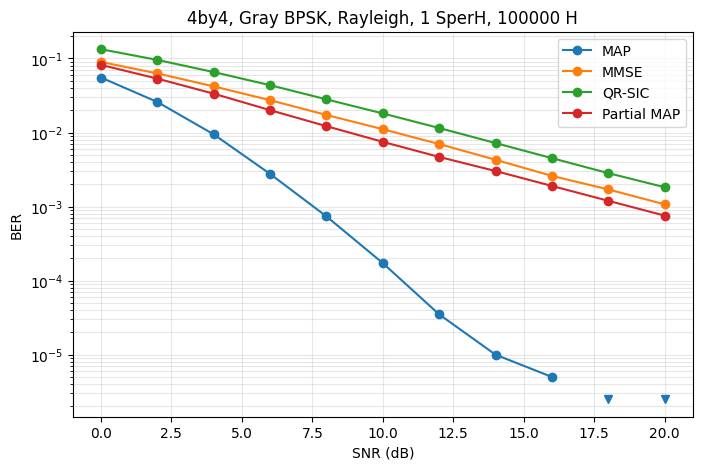

In [11]:
import matplotlib.pyplot as plt
import numpy as np

snr_db = np.asarray(SNR_DB)
fig, ax = plt.subplots(figsize=(8, 5))

for j, name in enumerate(models):
    points = ber[:, j]
    line, = ax.semilogy(
        snr_db, np.where(points > 0, points, np.nan), "o-", label=name
    )

    zero = points == 0
    if zero.any():
        ax.semilogy(
            snr_db[zero],
            np.full(zero.sum(), 1 / bits_per_snr),
            "v",
            color=line.get_color(),
        )

TITLE = f"{NT}by{NR}, Gray BPSK, Rayleigh, {SYMBOLS_PER_CHANNEL} SperH, {BLOCKS} H"
ax.set(xlabel="SNR (dB)", ylabel="BER",
       title=TITLE)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
print("Downward triangles: zero observed errors, shown at 1 / bits per SNR.")

plt.savefig(f'{TITLE}.png', dpi=300, bbox_inches='tight')
try:
    from google.colab import files
except ImportError:
    pass
else:
    files.download(ERROR_CSV)
    files.download(f'{TITLE}.png')

plt.show()